In [1]:
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data = pd.read_csv('Mall_Customers.csv')
print(data.shape)
data.head()

(200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
x = data.iloc[:, [2, 4]].values

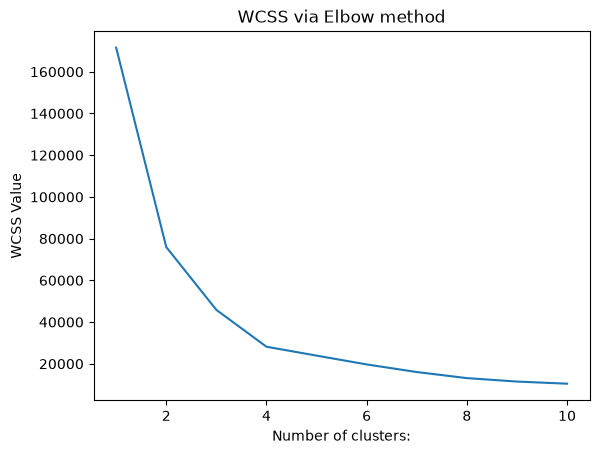

In [4]:
wcss = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, init='k-means++', random_state=21)
    model.fit(x)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss)
plt.title('WCSS via Elbow method')
plt.xlabel('Number of clusters:')
plt.ylabel('WCSS Value')
plt.show()

In [5]:
model = KMeans(n_clusters=4, init='k-means++', random_state=42)
y_means = model.fit_predict(x)
print(y_means)

[3 1 2 1 3 1 2 1 2 1 2 1 2 1 2 1 3 3 2 1 3 1 2 1 2 1 2 3 2 1 2 1 2 1 2 1 2
 1 2 1 0 1 0 3 2 3 0 3 3 3 0 3 3 0 0 0 0 0 3 0 0 3 0 0 0 3 0 0 3 3 0 0 0 0
 0 3 0 3 3 0 0 3 0 0 3 0 0 3 3 0 0 3 0 3 3 3 0 3 0 3 3 0 0 3 0 3 0 0 0 0 0
 3 3 3 3 3 0 0 0 0 3 3 3 1 3 1 0 1 2 1 2 1 3 1 2 1 2 1 2 1 2 1 3 1 2 1 0 1
 2 1 2 1 2 1 2 1 2 1 2 1 0 1 2 1 2 1 2 1 2 3 2 1 2 1 2 1 2 1 2 1 2 1 2 1 3
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]


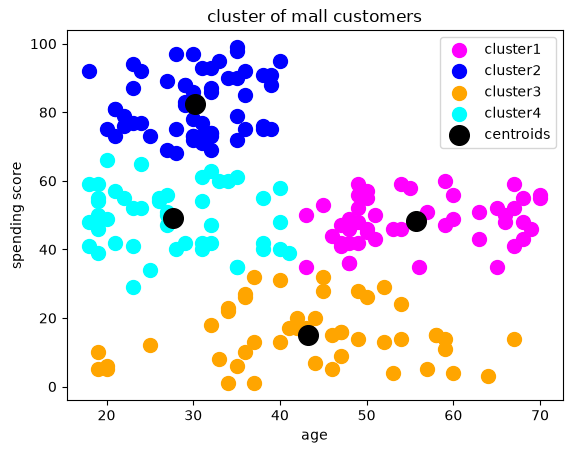

In [6]:
plt.scatter(x[y_means == 0, 0], x[y_means == 0, 1], s=100, c='magenta', label='cluster1')
plt.scatter(x[y_means == 1, 0], x[y_means == 1, 1], s=100, c='blue', label='cluster2')
plt.scatter(x[y_means == 2, 0], x[y_means == 2, 1], s=100, c='orange', label='cluster3')
plt.scatter(x[y_means == 3, 0], x[y_means == 3, 1], s=100, c='cyan', label='cluster4')
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], s=200, c='black', label='centroids')
plt.title('cluster of mall customers')
plt.xlabel('age')
plt.ylabel('spending score')
plt.legend()
plt.show()